Device: cuda


100%|██████████| 3.52G/3.52G [03:06<00:00, 20.2MB/s]

Extracting files...



Dataset path:
/root/.cache/kagglehub/datasets/gopalbhattrai/pascal-voc-2012-dataset/versions/1

VOC root:
/root/.cache/kagglehub/datasets/gopalbhattrai/pascal-voc-2012-dataset/versions/1/VOC2012_train_val/VOC2012_train_val
JPEGImages exists: True
SegmentationClass exists: True

Number of images: 17125
Number of masks : 2913
Matching image-mask pairs: 2913

Building class-wise image lists...


  0%|          | 0/2913 [00:00<?, ?it/s]


Class-wise image counts:
------------------------------------------------------------
 1 | aeroplane       |   178
 2 | bicycle         |   144
 3 | bird            |   208
 4 | boat            |   150
 5 | bottle          |   183
 6 | bus             |   152
 7 | car             |   255
 8 | cat             |   250
 9 | chair           |   271
10 | cow             |   135
11 | diningtable     |   157
12 | dog             |   249
13 | horse           |   147
14 | motorbike       |   157
15 | person          |   888
16 | pottedplant     |   167
17 | sheep           |   120
18 | sofa            |   183
19 | train           |   167
20 | tvmonitor       |   157


STARTING 4-FOLD FEW-SHOT TRAINING


FOLD 1
Training classes:
['bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']

Unseen test classes:
['aeroplane', 'bicycle', 'bird', 'boat', 'bottle']
Downloading: "https://download.pytorch.org/models/r

100%|██████████| 97.8M/97.8M [00:00<00:00, 134MB/s]



Model parameters:
Total     : 16,411,712
Trainable : 16,154,624
Fold 1 | Episode 001/1000 | Class: pottedplant     | Loss: 1.6841 | mIoU: 45.09% | FGIoU: 0.39%
Fold 1 | Episode 025/1000 | Class: sofa            | Loss: 1.5755 | mIoU: 32.39% | FGIoU: 8.97%
Fold 1 | Episode 050/1000 | Class: cow             | Loss: 0.8781 | mIoU: 81.45% | FGIoU: 80.85%
Fold 1 | Episode 075/1000 | Class: diningtable     | Loss: 1.1381 | mIoU: 17.81% | FGIoU: 28.99%
Fold 1 | Episode 100/1000 | Class: tvmonitor       | Loss: 1.6317 | mIoU: 35.33% | FGIoU: 2.16%
Fold 1 | Episode 125/1000 | Class: sheep           | Loss: 0.8322 | mIoU: 71.77% | FGIoU: 69.13%
Fold 1 | Episode 150/1000 | Class: diningtable     | Loss: 0.9727 | mIoU: 46.68% | FGIoU: 51.78%
Fold 1 | Episode 175/1000 | Class: pottedplant     | Loss: 1.6158 | mIoU: 27.06% | FGIoU: 1.93%
Fold 1 | Episode 200/1000 | Class: pottedplant     | Loss: 1.1599 | mIoU: 63.51% | FGIoU: 50.40%
Fold 1 | Episode 225/1000 | Class: train           | Loss: 0.9850 

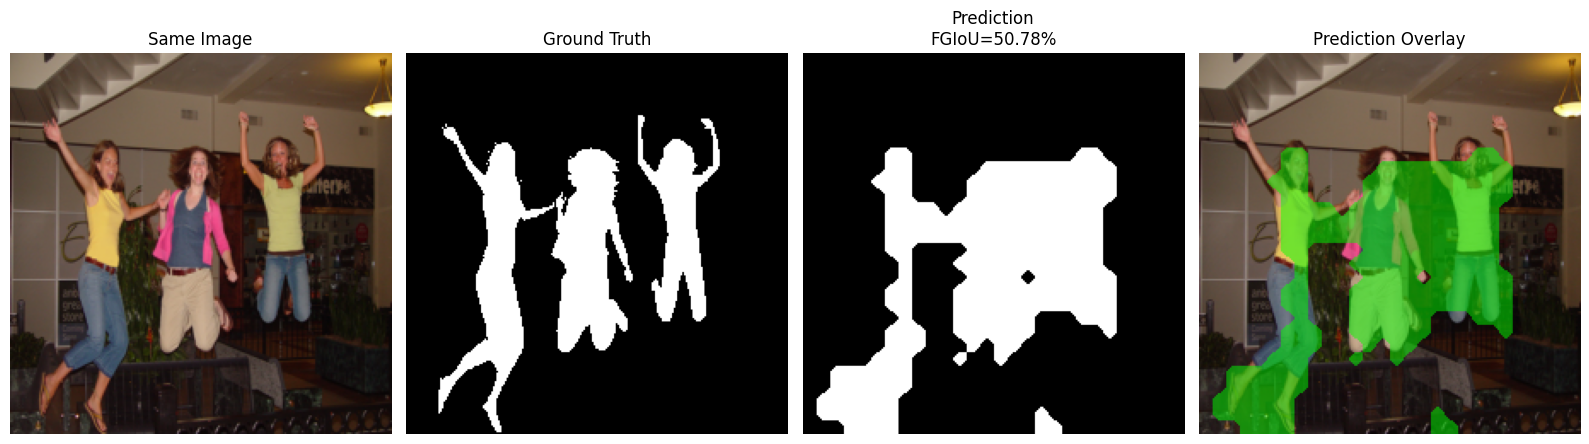


Saved: same_image_diagnostic.png


UNSEEN CLASS VISUALIZATION
Fold: 2
Unseen class: bus
mIoU : 49.23%
FGIoU: 44.43%
BGIoU: 54.02%


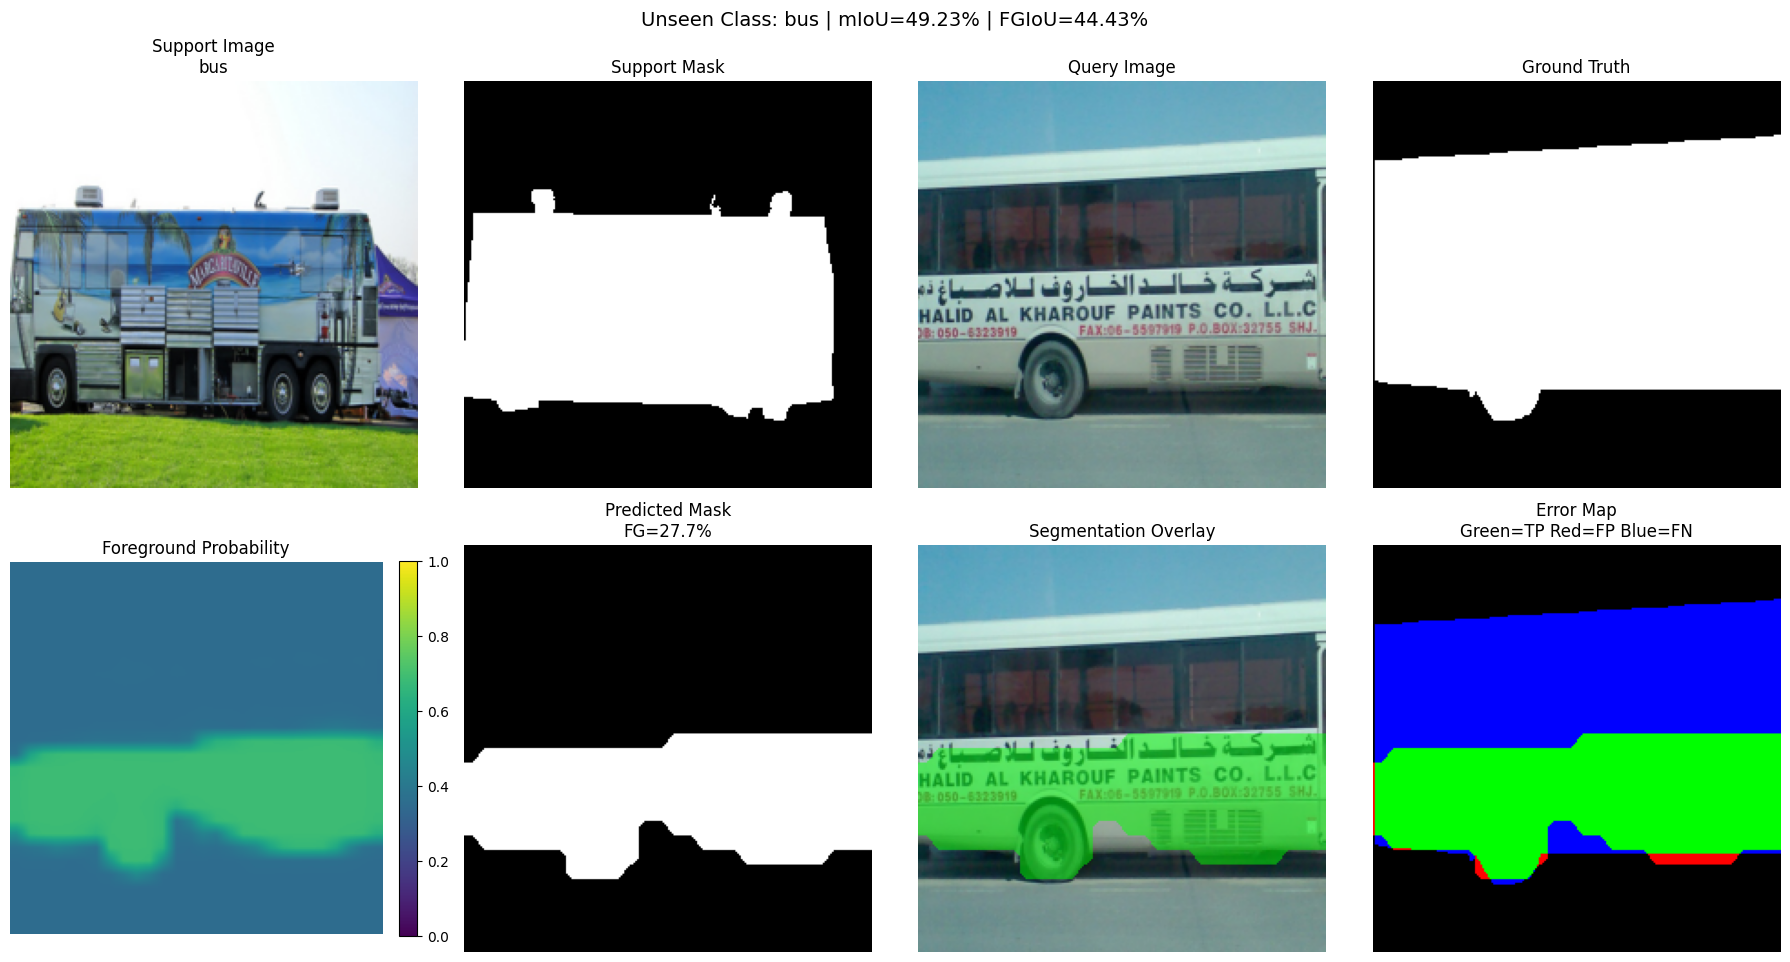


Saved: unseen_class_prediction.png


FINAL SUMMARY
Training mIoU  : 60.84%
Training FGIoU : 41.08%
Test mIoU      : 59.11%
Test FGIoU     : 38.34%
Test BGIoU     : 79.89%

Training complete.
Check these files:
1. same_image_diagnostic.png
2. unseen_class_prediction.png
3. fewshot_models/fold_1.pth
4. fewshot_models/fold_2.pth
5. fewshot_models/fold_3.pth
6. fewshot_models/fold_4.pth


In [ ]:
# ============================================================
# FEW-SHOT SEMANTIC SEGMENTATION ON PASCAL VOC 2012
# ============================================================
#
# Improved version:
#
# 1. ResNet50 pretrained backbone
# 2. Multi-scale features:
#       layer2 -> spatial information
#       layer3 -> semantic information
# 3. Feature fusion
# 4. Foreground + Background prototypes
# 5. K-shot support averaging
# 6. BCE + Dice loss
# 7. Episodic training
# 8. 4-fold unseen-class evaluation
# 9. Same-image diagnostic test
# 10. Visualization
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import models

from tqdm.auto import tqdm


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# For reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 3. DOWNLOAD DATASET
# ============================================================

import kagglehub

dataset_path = kagglehub.dataset_download(
    "gopalbhattrai/pascal-voc-2012-dataset"
)

print("\nDataset path:")
print(dataset_path)


# ============================================================
# 4. FIND VOC ROOT AUTOMATICALLY
# ============================================================

def find_voc_root(base_path):

    possible_paths = [

        os.path.join(
            base_path,
            "VOC2012_train_val",
            "VOC2012_train_val"
        ),

        os.path.join(
            base_path,
            "VOC2012_train_val"
        ),

        base_path
    ]

    for path in possible_paths:

        jpeg = os.path.join(path, "JPEGImages")
        masks = os.path.join(path, "SegmentationClass")

        if os.path.isdir(jpeg) and os.path.isdir(masks):
            return path

    # Recursive search
    for root, dirs, files in os.walk(base_path):

        if (
            os.path.basename(root) == "JPEGImages"
            and os.path.isdir(
                os.path.join(
                    os.path.dirname(root),
                    "SegmentationClass"
                )
            )
        ):

            return os.path.dirname(root)

    raise FileNotFoundError(
        "Could not find VOC2012 JPEGImages/SegmentationClass folders."
    )


VOC_ROOT = find_voc_root(dataset_path)

jpeg_dir = os.path.join(
    VOC_ROOT,
    "JPEGImages"
)

mask_dir = os.path.join(
    VOC_ROOT,
    "SegmentationClass"
)

print("\nVOC root:")
print(VOC_ROOT)

print(
    "JPEGImages exists:",
    os.path.exists(jpeg_dir)
)

print(
    "SegmentationClass exists:",
    os.path.exists(mask_dir)
)


# ============================================================
# 5. CHECK DATASET
# ============================================================

image_files = sorted([
    f for f in os.listdir(jpeg_dir)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

mask_files = sorted([
    f for f in os.listdir(mask_dir)
    if f.lower().endswith(".png")
])

print("\nNumber of images:", len(image_files))
print("Number of masks :", len(mask_files))


# ============================================================
# 6. IMAGE-MASK PAIRING
# ============================================================

image_dict = {
    os.path.splitext(f)[0]:
        os.path.join(jpeg_dir, f)
    for f in image_files
}

mask_dict = {
    os.path.splitext(f)[0]:
        os.path.join(mask_dir, f)
    for f in mask_files
}

common_ids = sorted(
    set(image_dict.keys()) &
    set(mask_dict.keys())
)

image_mask_pairs = [
    (
        image_dict[i],
        mask_dict[i]
    )
    for i in common_ids
]

print(
    "Matching image-mask pairs:",
    len(image_mask_pairs)
)


# ============================================================
# 7. PASCAL VOC CLASSES
# ============================================================

VOC_CLASSES = [
    "background",
    "aeroplane",
    "bicycle",
    "bird",
    "boat",
    "bottle",
    "bus",
    "car",
    "cat",
    "chair",
    "cow",
    "diningtable",
    "dog",
    "horse",
    "motorbike",
    "person",
    "pottedplant",
    "sheep",
    "sofa",
    "train",
    "tvmonitor"
]

NUM_CLASSES = 20


# ============================================================
# 8. VOC MASK DECODER
# ============================================================

def decode_voc_mask(mask_path):

    mask = Image.open(mask_path)

    mask_array = np.array(mask)

    # Standard VOC masks are indexed PNG
    if mask_array.ndim == 2:

        return mask_array.astype(np.uint8)

    # Fallback for RGB encoded masks
    rgb = np.array(
        mask.convert("RGB")
    )

    class_mask = np.zeros(
        rgb.shape[:2],
        dtype=np.uint8
    )

    # VOC color decoding
    for class_id in range(21):

        color = [0, 0, 0]

        value = class_id

        for j in range(8):

            color[0] |= (
                ((value >> 0) & 1)
                << j
            )

            color[1] |= (
                ((value >> 1) & 1)
                << j
            )

            color[2] |= (
                ((value >> 2) & 1)
                << j
            )

            value >>= 3

        matches = np.all(
            rgb == np.array(color),
            axis=2
        )

        class_mask[matches] = class_id

    return class_mask


# ============================================================
# 9. BUILD CLASS-WISE IMAGE LIST
# ============================================================

class_images = {
    class_id: []
    for class_id in range(1, 21)
}

print("\nBuilding class-wise image lists...")

for image_path, mask_path in tqdm(
    image_mask_pairs
):

    mask = decode_voc_mask(mask_path)

    present_classes = np.unique(mask)

    for class_id in present_classes:

        class_id = int(class_id)

        # Background
        if class_id == 0:
            continue

        # Ignore VOC void label
        if class_id == 255:
            continue

        if 1 <= class_id <= 20:

            class_images[class_id].append(
                (
                    image_path,
                    mask_path
                )
            )


print("\nClass-wise image counts:")
print("-" * 60)

for class_id in range(1, 21):

    print(
        f"{class_id:2d} | "
        f"{VOC_CLASSES[class_id]:15s} | "
        f"{len(class_images[class_id]):5d}"
    )


# ============================================================
# 10. SETTINGS
# ============================================================

IMAGE_SIZE = 224

K_SHOT = 5

# Training
EPISODES_PER_FOLD = 1000

# Testing
EPISODES_PER_TEST_FOLD = 100

# Learning rate
LEARNING_RATE = 1e-4

# Weight decay
WEIGHT_DECAY = 1e-5

# Feature dimension
FEATURE_DIM = 512

# Number of folds
NUM_FOLDS = 4


# ============================================================
# 11. IMAGE PREPROCESSING
# ============================================================

weights = models.ResNet50_Weights.DEFAULT

preprocess = weights.transforms()


def load_image(image_path):

    image = Image.open(
        image_path
    ).convert("RGB")

    resized_image = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.BILINEAR
    )

    image_np = np.array(
        resized_image
    )

    tensor = preprocess(
        resized_image
    )

    return image_np, tensor


# ============================================================
# 12. BINARY MASK
# ============================================================

def load_binary_mask(
    mask_path,
    class_id
):

    mask = decode_voc_mask(
        mask_path
    )

    # Only requested class = foreground
    binary_mask = (
        mask == class_id
    ).astype(np.uint8)

    binary_mask = cv2.resize(
        binary_mask,
        (
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )

    return binary_mask


# ============================================================
# 13. BATCHNORM FREEZING
# ============================================================

def freeze_bn(module):

    if isinstance(
        module,
        nn.BatchNorm2d
    ):

        module.eval()

        if module.weight is not None:
            module.weight.requires_grad = False

        if module.bias is not None:
            module.bias.requires_grad = False


# ============================================================
# 14. MULTI-SCALE RESNET50 BACKBONE
# ============================================================

class MultiScaleResNet50(nn.Module):

    def __init__(
        self,
        feature_dim=256
    ):

        super().__init__()

        # Pretrained ResNet50
        resnet = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        # Initial layers
        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool

        # ResNet stages
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3

        # layer2 output = 512 channels
        self.proj_layer2 = nn.Sequential(

            nn.Conv2d(
                512,
                feature_dim,
                kernel_size=1,
                bias=False
            ),

            nn.BatchNorm2d(
                feature_dim
            ),

            nn.ReLU(inplace=True)
        )

        # layer3 output = 1024 channels
        self.proj_layer3 = nn.Sequential(

            nn.Conv2d(
                1024,
                feature_dim,
                kernel_size=1,
                bias=False
            ),

            nn.BatchNorm2d(
                feature_dim
            ),

            nn.ReLU(inplace=True)
        )

        # Fusion
        self.fusion = nn.Sequential(

            nn.Conv2d(
                feature_dim * 2,
                feature_dim,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                feature_dim
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                feature_dim,
                feature_dim,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                feature_dim
            ),

            nn.ReLU(inplace=True)
        )

        self._initialize_new_layers()

    def _initialize_new_layers(self):

        for module in [

            self.proj_layer2,
            self.proj_layer3,
            self.fusion

        ]:

            for m in module.modules():

                if isinstance(
                    m,
                    nn.Conv2d
                ):

                    nn.init.kaiming_normal_(
                        m.weight,
                        mode="fan_out",
                        nonlinearity="relu"
                    )

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)

        # layer2:
        # approximately 28 x 28
        feature2 = self.layer2(x)

        # layer3:
        # approximately 14 x 14
        feature3 = self.layer3(
            feature2
        )

        feature2 = self.proj_layer2(
            feature2
        )

        feature3 = self.proj_layer3(
            feature3
        )

        # Bring layer3 to layer2 resolution
        feature3 = F.interpolate(
            feature3,
            size=feature2.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Multi-scale fusion
        fused = torch.cat(
            [
                feature2,
                feature3
            ],
            dim=1
        )

        fused = self.fusion(
            fused
        )

        return fused


# ============================================================
# 15. CREATE BACKBONE
# ============================================================

def create_backbone():

    model = MultiScaleResNet50(
        feature_dim=FEATURE_DIM
    )

    # --------------------------------------------------------
    # Freeze very early layers
    # --------------------------------------------------------

    for module in [

        model.conv1,
        model.bn1,
        model.layer1

    ]:

        for p in module.parameters():
            p.requires_grad = False

    # --------------------------------------------------------
    # Train layer2, layer3 and fusion
    # --------------------------------------------------------

    for module in [

        model.layer2,
        model.layer3,
        model.proj_layer2,
        model.proj_layer3,
        model.fusion

    ]:

        for p in module.parameters():
            p.requires_grad = True

    # Freeze BatchNorm statistics
    model.apply(
        freeze_bn
    )

    return model.to(device)


# ============================================================
# 16. FEATURE EXTRACTION
# ============================================================

def extract_feature(
    model,
    image_tensor
):

    image_tensor = (
        image_tensor
        .unsqueeze(0)
        .to(device)
    )

    feature = model(
        image_tensor
    )

    return feature.squeeze(0)


# ============================================================
# 17. PROTOTYPE CALCULATION
# ============================================================

def calculate_prototypes(
    feature,
    mask
):

    """
    feature:
        [C, H, W]

    mask:
        [224, 224]

    Returns:
        foreground prototype
        background prototype
    """

    # Resize mask to feature resolution
    mask = (
        mask
        .unsqueeze(0)
        .unsqueeze(0)
        .float()
        .to(feature.device)
    )

    mask = F.interpolate(
        mask,
        size=feature.shape[-2:],
        mode="nearest"
    )

    mask = mask.squeeze(
        0
    ).squeeze(
        0
    )

    fg_mask = mask

    bg_mask = 1.0 - mask

    eps = 1e-6

    # --------------------------------------------------------
    # Foreground prototype
    # --------------------------------------------------------

    fg_sum = (
        feature *
        fg_mask.unsqueeze(0)
    ).sum(
        dim=(1, 2)
    )

    fg_count = (
        fg_mask.sum() +
        eps
    )

    fg_prototype = (
        fg_sum /
        fg_count
    )

    fg_prototype = F.normalize(
        fg_prototype,
        dim=0
    )

    # --------------------------------------------------------
    # Background prototype
    # --------------------------------------------------------

    bg_sum = (
        feature *
        bg_mask.unsqueeze(0)
    ).sum(
        dim=(1, 2)
    )

    bg_count = (
        bg_mask.sum() +
        eps
    )

    bg_prototype = (
        bg_sum /
        bg_count
    )

    bg_prototype = F.normalize(
        bg_prototype,
        dim=0
    )

    return (
        fg_prototype,
        bg_prototype
    )


# ============================================================
# 18. K-SHOT PROTOTYPES
# ============================================================

def compute_kshot_prototypes(
    model,
    episode
):

    fg_prototypes = []

    bg_prototypes = []

    for tensor, mask_np in zip(

        episode["support_tensors"],
        episode["support_masks"]

    ):

        feature = extract_feature(
            model,
            tensor
        )

        mask_tensor = torch.from_numpy(
            mask_np
        ).float().to(device)

        fg_proto, bg_proto = (
            calculate_prototypes(
                feature,
                mask_tensor
            )
        )

        fg_prototypes.append(
            fg_proto
        )

        bg_prototypes.append(
            bg_proto
        )

    if len(fg_prototypes) == 0:
        return None, None

    # Average K support prototypes
    fg_prototype = torch.stack(
        fg_prototypes,
        dim=0
    ).mean(
        dim=0
    )

    bg_prototype = torch.stack(
        bg_prototypes,
        dim=0
    ).mean(
        dim=0
    )

    # Normalize again
    fg_prototype = F.normalize(
        fg_prototype,
        dim=0
    )

    bg_prototype = F.normalize(
        bg_prototype,
        dim=0
    )

    return (
        fg_prototype,
        bg_prototype
    )


# ============================================================
# 19. FG/BG SIMILARITY
# ============================================================

def calculate_fg_bg_logits(
    feature,
    fg_prototype,
    bg_prototype
):

    feature = F.normalize(
        feature,
        dim=0
    )

    fg_prototype = F.normalize(
        fg_prototype,
        dim=0
    )

    bg_prototype = F.normalize(
        bg_prototype,
        dim=0
    )

    # --------------------------------------------------------
    # Foreground similarity
    # --------------------------------------------------------

    fg_similarity = torch.sum(
        feature *
        fg_prototype[:, None, None],
        dim=0
    )

    # --------------------------------------------------------
    # Background similarity
    # --------------------------------------------------------

    bg_similarity = torch.sum(
        feature *
        bg_prototype[:, None, None],
        dim=0
    )

    # --------------------------------------------------------
    # FG - BG
    #
    # positive = foreground
    # negative = background
    # --------------------------------------------------------

    logits = (
        fg_similarity -
        bg_similarity
    )

    return logits


# ============================================================
# 20. DICE LOSS
# ============================================================

def dice_loss(
    logits,
    target
):

    probability = torch.sigmoid(
        logits
    )

    smooth = 1.0

    intersection = (
        probability *
        target
    ).sum()

    dice = (

        2.0 * intersection +
        smooth

    ) / (

        probability.sum() +
        target.sum() +
        smooth

    )

    return 1.0 - dice


# ============================================================
# 21. COMBINED LOSS
# ============================================================

def segmentation_loss(
    logits,
    target
):

    bce = F.binary_cross_entropy_with_logits(
        logits,
        target
    )

    dice = dice_loss(
        logits,
        target
    )

    loss = (
        bce +
        dice
    )

    return loss, bce, dice


# ============================================================
# 22. PREDICTION
# ============================================================

def logits_to_prediction(
    logits,
    output_size=(224, 224)
):

    probability = torch.sigmoid(
        logits
    )

    prediction = (
        probability > 0.5
    ).float()

    prediction = F.interpolate(
        prediction
        .unsqueeze(0)
        .unsqueeze(0),

        size=output_size,

        mode="bilinear",

        align_corners=False
    )

    prediction = (
        prediction.squeeze()
        .detach()
        .cpu()
        .numpy()
    )

    # Convert back to binary
    prediction = (
        prediction > 0.5
    ).astype(np.uint8)

    return prediction


# ============================================================
# 23. METRICS
# ============================================================

def calculate_metrics(
    prediction,
    ground_truth
):

    prediction = (
        prediction.astype(bool)
    )

    ground_truth = (
        ground_truth.astype(bool)
    )

    # --------------------------------------------------------
    # Foreground IoU
    # --------------------------------------------------------

    fg_intersection = np.logical_and(
        prediction,
        ground_truth
    ).sum()

    fg_union = np.logical_or(
        prediction,
        ground_truth
    ).sum()

    if fg_union == 0:

        fg_iou = np.nan

    else:

        fg_iou = (
            fg_intersection /
            fg_union
        )

    # --------------------------------------------------------
    # Background IoU
    # --------------------------------------------------------

    prediction_bg = ~prediction

    ground_truth_bg = ~ground_truth

    bg_intersection = np.logical_and(
        prediction_bg,
        ground_truth_bg
    ).sum()

    bg_union = np.logical_or(
        prediction_bg,
        ground_truth_bg
    ).sum()

    if bg_union == 0:

        bg_iou = np.nan

    else:

        bg_iou = (
            bg_intersection /
            bg_union
        )

    # --------------------------------------------------------
    # mIoU
    # --------------------------------------------------------

    valid = [

        x for x in [
            fg_iou,
            bg_iou
        ]

        if np.isfinite(x)

    ]

    if len(valid) == 0:

        miou = np.nan

    else:

        miou = np.mean(
            valid
        )

    return (
        miou,
        fg_iou,
        bg_iou
    )


# ============================================================
# 24. CREATE EPISODE
# ============================================================

def create_episode(
    class_id,
    k_shot=K_SHOT
):

    if class_id not in class_images:
        return None

    samples = class_images[
        class_id
    ]

    if len(samples) < (
        k_shot + 1
    ):

        return None

    # Keep only valid paths
    valid_samples = [

        (img, msk)

        for img, msk in samples

        if (
            os.path.exists(img)
            and
            os.path.exists(msk)
        )

    ]

    if len(valid_samples) < (
        k_shot + 1
    ):

        return None

    # Random K+1
    chosen = random.sample(
        valid_samples,
        k_shot + 1
    )

    support_items = chosen[
        :k_shot
    ]

    query_item = chosen[
        k_shot
    ]

    support_images = []
    support_tensors = []
    support_masks = []

    # --------------------------------------------------------
    # Support
    # --------------------------------------------------------

    for (
        support_image_path,
        support_mask_path
    ) in support_items:

        support_image, support_tensor = (
            load_image(
                support_image_path
            )
        )

        support_mask = load_binary_mask(
            support_mask_path,
            class_id
        )

        if support_mask.sum() == 0:
            continue

        support_images.append(
            support_image
        )

        support_tensors.append(
            support_tensor
        )

        support_masks.append(
            support_mask
        )

    if len(support_tensors) == 0:
        return None

    # --------------------------------------------------------
    # Query
    # --------------------------------------------------------

    query_image_path, query_mask_path = (
        query_item
    )

    query_image, query_tensor = (
        load_image(
            query_image_path
        )
    )

    query_mask = load_binary_mask(
        query_mask_path,
        class_id
    )

    if query_mask.sum() == 0:
        return None

    return {

        "support_images":
            support_images,

        "support_tensors":
            support_tensors,

        "support_masks":
            support_masks,

        "support_image":
            support_images[0],

        "support_mask":
            support_masks[0],

        "query_image":
            query_image,

        "query_tensor":
            query_tensor,

        "query_mask":
            query_mask,

        "class_id":
            class_id

    }


# ============================================================
# 25. TRAIN ONE EPISODE
# ============================================================

def train_episode(
    model,
    optimizer,
    class_id
):

    episode = create_episode(
        class_id
    )

    if episode is None:
        return None

    query_tensor = (
        episode["query_tensor"]
    )

    query_mask = torch.from_numpy(
        episode["query_mask"]
    ).float().to(device)

    model.train()

    # Keep BN frozen
    model.apply(
        freeze_bn
    )

    optimizer.zero_grad()

    # --------------------------------------------------------
    # Support prototypes
    # --------------------------------------------------------

    fg_prototype, bg_prototype = (
        compute_kshot_prototypes(
            model,
            episode
        )
    )

    if fg_prototype is None:
        return None

    # --------------------------------------------------------
    # Query feature
    # --------------------------------------------------------

    query_feature = extract_feature(
        model,
        query_tensor
    )

    # --------------------------------------------------------
    # FG vs BG logits
    # --------------------------------------------------------

    logits = calculate_fg_bg_logits(
        query_feature,
        fg_prototype,
        bg_prototype
    )

    # --------------------------------------------------------
    # Ground truth at feature resolution
    # --------------------------------------------------------

    gt_small = F.interpolate(

        query_mask
        .unsqueeze(0)
        .unsqueeze(0),

        size=logits.shape,

        mode="nearest"

    ).squeeze()

    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    loss, bce, dice = (
        segmentation_loss(
            logits,
            gt_small
        )
    )

    if not torch.isfinite(loss):

        print(
            "Non-finite loss. Skipping."
        )

        return None

    # --------------------------------------------------------
    # Backpropagation
    # --------------------------------------------------------

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    prediction = logits_to_prediction(
        logits
    )

    miou, fgiou, bgiou = (
        calculate_metrics(
            prediction,
            episode["query_mask"]
        )
    )

    return {

        "loss":
            loss.item(),

        "bce":
            bce.item(),

        "dice":
            dice.item(),

        "mIoU":
            miou,

        "FGIoU":
            fgiou,

        "BGIoU":
            bgiou,

        "class_id":
            class_id

    }


# ============================================================
# 26. INFERENCE
# ============================================================

def inference_episode(
    model,
    class_id
):

    episode = create_episode(
        class_id
    )

    if episode is None:
        return None

    model.eval()

    with torch.no_grad():

        # ----------------------------------------------------
        # Support
        # ----------------------------------------------------

        fg_prototype, bg_prototype = (
            compute_kshot_prototypes(
                model,
                episode
            )
        )

        if fg_prototype is None:
            return None

        # ----------------------------------------------------
        # Query
        # ----------------------------------------------------

        query_feature = extract_feature(
            model,
            episode["query_tensor"]
        )

        # ----------------------------------------------------
        # FG/BG logits
        # ----------------------------------------------------

        logits = calculate_fg_bg_logits(
            query_feature,
            fg_prototype,
            bg_prototype
        )

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        prediction = logits_to_prediction(
            logits
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        miou, fgiou, bgiou = (
            calculate_metrics(
                prediction,
                episode["query_mask"]
            )
        )

        if not (
            np.isfinite(miou)
            and
            np.isfinite(fgiou)
        ):

            return None

        # Probability map
        probability = torch.sigmoid(
            logits
        )

        probability = F.interpolate(

            probability
            .unsqueeze(0)
            .unsqueeze(0),

            size=(224, 224),

            mode="bilinear",

            align_corners=False

        )

        probability = (
            probability.squeeze()
            .cpu()
            .numpy()
        )

        return {

            "mIoU":
                miou,

            "FGIoU":
                fgiou,

            "BGIoU":
                bgiou,

            "support_image":
                episode["support_image"],

            "support_mask":
                episode["support_mask"],

            "query_image":
                episode["query_image"],

            "query_mask":
                episode["query_mask"],

            "prediction":
                prediction,

            "probability":
                probability,

            "class_id":
                class_id

        }


# ============================================================
# 27. FOUR FOLDS
# ============================================================

FOLDS = [

    [1, 2, 3, 4, 5],

    [6, 7, 8, 9, 10],

    [11, 12, 13, 14, 15],

    [16, 17, 18, 19, 20]

]


# ============================================================
# 28. MODEL PARAMETER COUNT
# ============================================================

def print_model_info(model):

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print("\nModel parameters:")
    print(
        f"Total     : {total_params:,}"
    )

    print(
        f"Trainable : {trainable_params:,}"
    )


# ============================================================
# 29. TRAIN ALL FOUR FOLDS
# ============================================================

all_trained_models = {}

training_results = {}

print("\n")
print("=" * 80)
print("STARTING 4-FOLD FEW-SHOT TRAINING")
print("=" * 80)


for fold_idx, test_classes in enumerate(
    FOLDS,
    1
):

    print("\n")
    print("=" * 80)
    print(
        f"FOLD {fold_idx}"
    )
    print("=" * 80)

    train_classes = [

        c for c in range(1, 21)

        if c not in test_classes

    ]

    print(
        "Training classes:"
    )

    print([
        VOC_CLASSES[c]
        for c in train_classes
    ])

    print(
        "\nUnseen test classes:"
    )

    print([
        VOC_CLASSES[c]
        for c in test_classes
    ])

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = create_backbone()

    print_model_info(
        model
    )

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    optimizer = torch.optim.AdamW(

        filter(
            lambda p:
                p.requires_grad,
            model.parameters()
        ),

        lr=LEARNING_RATE,

        weight_decay=WEIGHT_DECAY
    )

    # Scheduler
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(

        optimizer,

        T_max=EPISODES_PER_FOLD

    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    losses = []
    mious = []
    fgiou_values = []

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    for episode_idx in range(
        1,
        EPISODES_PER_FOLD + 1
    ):

        class_id = random.choice(
            train_classes
        )

        result = train_episode(

            model,
            optimizer,
            class_id

        )

        scheduler.step()

        if result is None:
            continue

        loss = result["loss"]
        miou = result["mIoU"]
        fgiou = result["FGIoU"]

        if not (
            np.isfinite(loss)
            and
            np.isfinite(miou)
            and
            np.isfinite(fgiou)
        ):

            continue

        losses.append(
            loss
        )

        mious.append(
            miou
        )

        fgiou_values.append(
            fgiou
        )

        # ----------------------------------------------------
        # Logging
        # ----------------------------------------------------

        if (

            episode_idx == 1

            or

            episode_idx % 25 == 0

        ):

            print(

                f"Fold {fold_idx} | "
                f"Episode "
                f"{episode_idx:03d}/"
                f"{EPISODES_PER_FOLD} | "

                f"Class: "
                f"{VOC_CLASSES[class_id]:15s} | "

                f"Loss: "
                f"{loss:.4f} | "

                f"mIoU: "
                f"{miou * 100:.2f}% | "

                f"FGIoU: "
                f"{fgiou * 100:.2f}%"

            )

    # --------------------------------------------------------
    # Fold results
    # --------------------------------------------------------

    mean_loss = (
        np.mean(losses)
        if losses
        else np.nan
    )

    mean_miou = (
        np.mean(mious)
        if mious
        else np.nan
    )

    mean_fgiou = (
        np.mean(fgiou_values)
        if fgiou_values
        else np.nan
    )

    print("\n")
    print("-" * 80)
    print(
        f"FOLD {fold_idx} TRAINING RESULT"
    )
    print("-" * 80)

    print(
        f"Valid episodes : "
        f"{len(losses)}"
    )

    print(
        f"Average Loss   : "
        f"{mean_loss:.4f}"
    )

    print(
        f"Average mIoU   : "
        f"{mean_miou * 100:.2f}%"
    )

    print(
        f"Average FGIoU  : "
        f"{mean_fgiou * 100:.2f}%"
    )

    print("-" * 80)

    # Save model in memory
    all_trained_models[
        fold_idx
    ] = model

    training_results[
        fold_idx
    ] = {

        "loss":
            mean_loss,

        "mIoU":
            mean_miou,

        "FGIoU":
            mean_fgiou

    }


# ============================================================
# 30. OVERALL TRAINING RESULTS
# ============================================================

train_mious = [

    training_results[f]["mIoU"]

    for f in training_results

    if np.isfinite(
        training_results[f]["mIoU"]
    )

]

train_fgiou = [

    training_results[f]["FGIoU"]

    for f in training_results

    if np.isfinite(
        training_results[f]["FGIoU"]
    )

]

overall_train_miou = (
    np.mean(train_mious)
    if train_mious
    else np.nan
)

overall_train_fgiou = (
    np.mean(train_fgiou)
    if train_fgiou
    else np.nan
)


print("\n")
print("=" * 80)
print("OVERALL TRAINING RESULT")
print("=" * 80)

for fold_idx in training_results:

    print(

        f"Fold {fold_idx} | "

        f"mIoU: "
        f"{training_results[fold_idx]['mIoU'] * 100:.2f}% | "

        f"FGIoU: "
        f"{training_results[fold_idx]['FGIoU'] * 100:.2f}%"

    )

print("-" * 80)

print(
    f"Overall Training mIoU : "
    f"{overall_train_miou * 100:.2f}%"
)

print(
    f"Overall Training FGIoU: "
    f"{overall_train_fgiou * 100:.2f}%"
)


# ============================================================
# 31. SAVE TRAINED MODELS
# ============================================================

MODEL_DIR = "fewshot_models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

for fold_idx, model in (
    all_trained_models.items()
):

    save_path = os.path.join(

        MODEL_DIR,

        f"fold_{fold_idx}.pth"

    )

    torch.save(

        model.state_dict(),

        save_path

    )

    print(
        "Saved:",
        save_path
    )


# ============================================================
# 32. UNSEEN CLASS INFERENCE
# ============================================================

inference_results = {}


print("\n")
print("=" * 80)
print("STARTING UNSEEN-CLASS INFERENCE")
print("=" * 80)


for fold_idx, test_classes in enumerate(
    FOLDS,
    1
):

    print("\n")
    print("=" * 80)

    print(
        f"INFERENCE — FOLD {fold_idx}"
    )

    print("=" * 80)

    print(
        "Unseen classes:"
    )

    print([
        VOC_CLASSES[c]
        for c in test_classes
    ])

    model = all_trained_models[
        fold_idx
    ]

    fold_mious = []
    fold_fgiou = []
    fold_bgiou = []

    for episode_idx in range(

        1,
        EPISODES_PER_TEST_FOLD + 1

    ):

        class_id = random.choice(
            test_classes
        )

        result = inference_episode(

            model,
            class_id

        )

        if result is None:
            continue

        fold_mious.append(
            result["mIoU"]
        )

        fold_fgiou.append(
            result["FGIoU"]
        )

        fold_bgiou.append(
            result["BGIoU"]
        )

        if (

            episode_idx == 1

            or

            episode_idx % 20 == 0

        ):

            print(

                f"Fold {fold_idx} | "
                f"Episode "
                f"{episode_idx:03d}/"
                f"{EPISODES_PER_TEST_FOLD} | "

                f"Class: "
                f"{VOC_CLASSES[class_id]:15s} | "

                f"mIoU: "
                f"{result['mIoU'] * 100:.2f}% | "

                f"FGIoU: "
                f"{result['FGIoU'] * 100:.2f}%"

            )

    # --------------------------------------------------------
    # Fold test results
    # --------------------------------------------------------

    mean_miou = (

        np.mean(fold_mious)

        if fold_mious

        else np.nan

    )

    mean_fgiou = (

        np.mean(fold_fgiou)

        if fold_fgiou

        else np.nan

    )

    mean_bgiou = (

        np.mean(fold_bgiou)

        if fold_bgiou

        else np.nan

    )

    inference_results[
        fold_idx
    ] = {

        "mIoU":
            mean_miou,

        "FGIoU":
            mean_fgiou,

        "BGIoU":
            mean_bgiou

    }

    print("\n")
    print("-" * 80)

    print(
        f"FOLD {fold_idx} INFERENCE RESULT"
    )

    print("-" * 80)

    print(
        f"Valid episodes : "
        f"{len(fold_mious)}"
    )

    print(
        f"Average mIoU   : "
        f"{mean_miou * 100:.2f}%"
    )

    print(
        f"Average FGIoU  : "
        f"{mean_fgiou * 100:.2f}%"
    )

    print(
        f"Average BGIoU  : "
        f"{mean_bgiou * 100:.2f}%"
    )

    print("-" * 80)


# ============================================================
# 33. FINAL TEST RESULT
# ============================================================

test_mious = [

    inference_results[f]["mIoU"]

    for f in inference_results

    if np.isfinite(
        inference_results[f]["mIoU"]
    )

]

test_fgiou = [

    inference_results[f]["FGIoU"]

    for f in inference_results

    if np.isfinite(
        inference_results[f]["FGIoU"]
    )

]

test_bgiou = [

    inference_results[f]["BGIoU"]

    for f in inference_results

    if np.isfinite(
        inference_results[f]["BGIoU"]
    )

]


overall_test_miou = (

    np.mean(test_mious)

    if test_mious

    else np.nan

)

overall_test_fgiou = (

    np.mean(test_fgiou)

    if test_fgiou

    else np.nan

)

overall_test_bgiou = (

    np.mean(test_bgiou)

    if test_bgiou

    else np.nan

)


print("\n")
print("=" * 80)
print("FINAL OVERALL TEST RESULT")
print("=" * 80)


for fold_idx in inference_results:

    print(

        f"Fold {fold_idx} | "

        f"mIoU: "
        f"{inference_results[fold_idx]['mIoU'] * 100:.2f}% | "

        f"FGIoU: "
        f"{inference_results[fold_idx]['FGIoU'] * 100:.2f}% | "

        f"BGIoU: "
        f"{inference_results[fold_idx]['BGIoU'] * 100:.2f}%"

    )


print("-" * 80)

print(
    f"FINAL TEST mIoU : "
    f"{overall_test_miou * 100:.2f}%"
)

print(
    f"FINAL TEST FGIoU: "
    f"{overall_test_fgiou * 100:.2f}%"
)

print(
    f"FINAL TEST BGIoU: "
    f"{overall_test_bgiou * 100:.2f}%"
)


# ============================================================
# 34. SAME-IMAGE DIAGNOSTIC TEST
# ============================================================
#
# VERY IMPORTANT:
#
# Before judging unseen-class performance,
# check whether the network can segment an object
# when SUPPORT and QUERY are from the SAME IMAGE.
#
# If same-image segmentation is poor:
#
#       problem = feature/prototype/loss
#
# If same-image segmentation is good but
# unseen-class segmentation is poor:
#
#       problem = generalization
#
# ============================================================


def create_same_image_episode(
    class_id
):

    samples = class_images[
        class_id
    ]

    if len(samples) == 0:
        return None

    # Random image
    image_path, mask_path = random.choice(
        samples
    )

    image_np, tensor = load_image(
        image_path
    )

    mask = load_binary_mask(
        mask_path,
        class_id
    )

    if mask.sum() == 0:
        return None

    return {

        "image":
            image_np,

        "tensor":
            tensor,

        "mask":
            mask,

        "class_id":
            class_id,

        "image_path":
            image_path

    }


def same_image_diagnostic(
    model,
    class_id
):

    episode = None

    for _ in range(20):

        episode = create_same_image_episode(
            class_id
        )

        if episode is not None:
            break

    if episode is None:

        print(
            "Could not create diagnostic episode."
        )

        return None

    model.eval()

    with torch.no_grad():

        feature = extract_feature(

            model,

            episode["tensor"]

        )

        mask_tensor = torch.from_numpy(

            episode["mask"]

        ).float().to(device)

        # ----------------------------------------------------
        # Prototype from same image
        # ----------------------------------------------------

        fg_proto, bg_proto = (
            calculate_prototypes(
                feature,
                mask_tensor
            )
        )

        # ----------------------------------------------------
        # Query = SAME IMAGE
        # ----------------------------------------------------

        logits = calculate_fg_bg_logits(

            feature,

            fg_proto,

            bg_proto

        )

        prediction = logits_to_prediction(
            logits
        )

        miou, fgiou, bgiou = (
            calculate_metrics(

                prediction,

                episode["mask"]

            )
        )

    return {

        "image":
            episode["image"],

        "ground_truth":
            episode["mask"],

        "prediction":
            prediction,

        "mIoU":
            miou,

        "FGIoU":
            fgiou,

        "BGIoU":
            bgiou,

        "class_id":
            class_id,

        "image_path":
            episode["image_path"]

    }


# ============================================================
# 35. RUN SAME-IMAGE DIAGNOSTIC
# ============================================================

print("\n")
print("=" * 80)
print("SAME-IMAGE DIAGNOSTIC")
print("=" * 80)


# Use fold 1 model
diagnostic_model = all_trained_models[1]

# One class from fold 1 training classes
diagnostic_class = 15

diagnostic_result = same_image_diagnostic(

    diagnostic_model,

    diagnostic_class

)


if diagnostic_result is not None:

    print(
        "\nDiagnostic class:",
        VOC_CLASSES[
            diagnostic_result["class_id"]
        ]
    )

    print(
        "Image:",
        diagnostic_result["image_path"]
    )

    print(
        f"Same-image mIoU : "
        f"{diagnostic_result['mIoU'] * 100:.2f}%"
    )

    print(
        f"Same-image FGIoU: "
        f"{diagnostic_result['FGIoU'] * 100:.2f}%"
    )

    print(
        f"Same-image BGIoU: "
        f"{diagnostic_result['BGIoU'] * 100:.2f}%"
    )


# ============================================================
# 36. VISUALIZE SAME-IMAGE DIAGNOSTIC
# ============================================================

if diagnostic_result is not None:

    image = diagnostic_result[
        "image"
    ]

    gt = diagnostic_result[
        "ground_truth"
    ]

    pred = diagnostic_result[
        "prediction"
    ]

    # Green overlay
    overlay = image.copy()

    green = np.zeros_like(
        image
    )

    green[:, :, 1] = 255

    alpha = 0.5

    foreground = (
        pred == 1
    )

    overlay[foreground] = (

        alpha *
        green[foreground]

        +

        (1 - alpha) *
        image[foreground]

    ).astype(np.uint8)

    plt.figure(
        figsize=(16, 8)
    )

    # Original
    plt.subplot(
        1, 4, 1
    )

    plt.imshow(
        image
    )

    plt.title(
        "Same Image"
    )

    plt.axis(
        "off"
    )

    # Ground truth
    plt.subplot(
        1, 4, 2
    )

    plt.imshow(
        gt,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(
        "Ground Truth"
    )

    plt.axis(
        "off"
    )

    # Prediction
    plt.subplot(
        1, 4, 3
    )

    plt.imshow(
        pred,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(

        "Prediction\n"
        f"FGIoU="
        f"{diagnostic_result['FGIoU'] * 100:.2f}%"

    )

    plt.axis(
        "off"
    )

    # Overlay
    plt.subplot(
        1, 4, 4
    )

    plt.imshow(
        overlay
    )

    plt.title(
        "Prediction Overlay"
    )

    plt.axis(
        "off"
    )

    plt.tight_layout()

    plt.savefig(
        "same_image_diagnostic.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print(
        "\nSaved:"
        " same_image_diagnostic.png"
    )


# ============================================================
# 37. VISUALIZE UNSEEN CLASS
# ============================================================

print("\n")
print("=" * 80)
print("UNSEEN CLASS VISUALIZATION")
print("=" * 80)


# Random fold
random_fold = random.choice(
    list(
        all_trained_models.keys()
    )
)

model = all_trained_models[
    random_fold
]

test_classes = FOLDS[
    random_fold - 1
]

random_class = random.choice(
    test_classes
)


print(
    "Fold:",
    random_fold
)

print(
    "Unseen class:",
    VOC_CLASSES[random_class]
)


result = None

for attempt in range(30):

    result = inference_episode(

        model,

        random_class

    )

    if result is not None:
        break


if result is None:

    print(
        "Could not create valid "
        "unseen-class visualization."
    )

else:

    support_image = result[
        "support_image"
    ]

    support_mask = result[
        "support_mask"
    ]

    query_image = result[
        "query_image"
    ]

    query_gt = result[
        "query_mask"
    ]

    prediction = result[
        "prediction"
    ]

    probability = result[
        "probability"
    ]

    print(
        f"mIoU : "
        f"{result['mIoU'] * 100:.2f}%"
    )

    print(
        f"FGIoU: "
        f"{result['FGIoU'] * 100:.2f}%"
    )

    print(
        f"BGIoU: "
        f"{result['BGIoU'] * 100:.2f}%"
    )

    # --------------------------------------------------------
    # Overlay
    # --------------------------------------------------------

    segmented_image = (
        query_image.copy()
    )

    green = np.zeros_like(
        segmented_image
    )

    green[:, :, 1] = 255

    alpha = 0.5

    foreground = (
        prediction == 1
    )

    segmented_image[
        foreground
    ] = (

        alpha *
        green[foreground]

        +

        (1 - alpha) *
        query_image[foreground]

    ).astype(np.uint8)

    # --------------------------------------------------------
    # Error map
    # --------------------------------------------------------

    gt_bool = (
        query_gt == 1
    )

    pred_bool = (
        prediction == 1
    )

    true_positive = (
        gt_bool &
        pred_bool
    )

    false_positive = (
        ~gt_bool &
        pred_bool
    )

    false_negative = (
        gt_bool &
        ~pred_bool
    )

    error_map = np.zeros_like(
        query_image
    )

    # TP
    error_map[
        true_positive
    ] = [0, 255, 0]

    # FP
    error_map[
        false_positive
    ] = [255, 0, 0]

    # FN
    error_map[
        false_negative
    ] = [0, 0, 255]

    # --------------------------------------------------------
    # Foreground percentage
    # --------------------------------------------------------

    fg_percentage = (
        prediction.mean()
        * 100
    )

    # --------------------------------------------------------
    # Visualization
    # --------------------------------------------------------

    plt.figure(
        figsize=(18, 10)
    )

    # 1 Support image
    plt.subplot(
        2, 4, 1
    )

    plt.imshow(
        support_image
    )

    plt.title(
        "Support Image\n"
        f"{VOC_CLASSES[random_class]}"
    )

    plt.axis(
        "off"
    )

    # 2 Support mask
    plt.subplot(
        2, 4, 2
    )

    plt.imshow(
        support_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(
        "Support Mask"
    )

    plt.axis(
        "off"
    )

    # 3 Query
    plt.subplot(
        2, 4, 3
    )

    plt.imshow(
        query_image
    )

    plt.title(
        "Query Image"
    )

    plt.axis(
        "off"
    )

    # 4 Ground truth
    plt.subplot(
        2, 4, 4
    )

    plt.imshow(
        query_gt,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(
        "Ground Truth"
    )

    plt.axis(
        "off"
    )

    # 5 Probability
    plt.subplot(
        2, 4, 5
    )

    plt.imshow(
        probability,
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    plt.colorbar(
        fraction=0.046,
        pad=0.04
    )

    plt.title(
        "Foreground Probability"
    )

    plt.axis(
        "off"
    )

    # 6 Prediction
    plt.subplot(
        2, 4, 6
    )

    plt.imshow(
        prediction,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(

        "Predicted Mask\n"
        f"FG={fg_percentage:.1f}%"

    )

    plt.axis(
        "off"
    )

    # 7 Overlay
    plt.subplot(
        2, 4, 7
    )

    plt.imshow(
        segmented_image
    )

    plt.title(
        "Segmentation Overlay"
    )

    plt.axis(
        "off"
    )

    # 8 Error
    plt.subplot(
        2, 4, 8
    )

    plt.imshow(
        error_map
    )

    plt.title(
        "Error Map\n"
        "Green=TP Red=FP Blue=FN"
    )

    plt.axis(
        "off"
    )

    plt.suptitle(

        f"Unseen Class: "
        f"{VOC_CLASSES[random_class]} | "

        f"mIoU="
        f"{result['mIoU'] * 100:.2f}% | "

        f"FGIoU="
        f"{result['FGIoU'] * 100:.2f}%",

        fontsize=14

    )

    plt.tight_layout()

    plt.savefig(

        "unseen_class_prediction.png",

        dpi=150,

        bbox_inches="tight"

    )

    plt.show()

    print(
        "\nSaved:"
        " unseen_class_prediction.png"
    )


# ============================================================
# 38. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 80)
print("FINAL SUMMARY")
print("=" * 80)

print(
    f"Training mIoU  : "
    f"{overall_train_miou * 100:.2f}%"
)

print(
    f"Training FGIoU : "
    f"{overall_train_fgiou * 100:.2f}%"
)

print(
    f"Test mIoU      : "
    f"{overall_test_miou * 100:.2f}%"
)

print(
    f"Test FGIoU     : "
    f"{overall_test_fgiou * 100:.2f}%"
)

print(
    f"Test BGIoU     : "
    f"{overall_test_bgiou * 100:.2f}%"
)

print("=" * 80)

print(
    "\nTraining complete."
)

print(
    "Check these files:"
)

print(
    "1. same_image_diagnostic.png"
)

print(
    "2. unseen_class_prediction.png"
)

print(
    f"3. {MODEL_DIR}/fold_1.pth"
)

print(
    f"4. {MODEL_DIR}/fold_2.pth"
)

print(
    f"5. {MODEL_DIR}/fold_3.pth"
)

print(
    f"6. {MODEL_DIR}/fold_4.pth"
)